<a href="https://colab.research.google.com/github/AdiRatnam/Cardiac_Risk_Prediction/blob/main/Week1_Module1_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import torch
from google.colab import drive

# Set device to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

# Mount Google Drive
drive.mount('/content/drive')

# Set project directory inside Drive
PROJECT_DIR = '/content/drive/MyDrive/Cardiac_Risk_Prediction'
os.makedirs(f'{PROJECT_DIR}/checkpoints', exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/outputs', exist_ok=True)

print(f"Working directory permanently mapped to: {PROJECT_DIR}")

Using compute device: cuda
Mounted at /content/drive
Working directory permanently mapped to: /content/drive/MyDrive/Cardiac_Risk_Prediction


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

def load_clinical_metadata(n_samples=2000):
    np.random.seed(42)
    age = np.random.randint(25, 85, size=n_samples)
    bmi = np.random.normal(26.5, 4.5, size=n_samples).clip(15, 45)
    systolic_bp = np.random.normal(125, 18, size=n_samples).clip(80, 200)
    cholesterol = np.random.normal(210, 40, size=n_samples).clip(120, 350)
    max_hr = (220 - age) - np.random.normal(10, 8, size=n_samples)

    risk_score = (
        0.03 * (age - 50) +
        0.04 * (bmi - 25) +
        0.02 * (systolic_bp - 120) +
        0.01 * (cholesterol - 200) -
        0.02 * (max_hr - 140)
    )
    prob = 1 / (1 + np.exp(-risk_score))
    y = (prob > 0.5).astype(np.float32)

    df = pd.DataFrame({
        'age': age,
        'bmi': bmi,
        'systolic_bp': systolic_bp,
        'cholesterol': cholesterol,
        'max_hr': max_hr
    })
    return df, y

# Generate and split
X, y = load_clinical_metadata(n_samples=2000)
X_train_df, X_val_df, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_df).astype(np.float32)
X_val = scaler.transform(X_val_df).astype(np.float32)

# Convert to PyTorch Tensors & DataLoaders
train_dataset = TensorDataset(torch.tensor(X_train), torch.tensor(y_train).unsqueeze(1))
val_dataset = TensorDataset(torch.tensor(X_val), torch.tensor(y_val).unsqueeze(1))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print(f"Data ready! Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")

Data ready! Train batches: 50 | Val batches: 13


No checkpoint found. Starting full PyTorch training loop...
Epoch [01/50] | Train Loss: 0.5788 | Val Loss: 0.3338 | Val AUC: 0.9812
Epoch [10/50] | Train Loss: 0.1707 | Val Loss: 0.1027 | Val AUC: 0.9987
Epoch [20/50] | Train Loss: 0.1753 | Val Loss: 0.0839 | Val AUC: 0.9987
Epoch [30/50] | Train Loss: 0.1413 | Val Loss: 0.0725 | Val AUC: 0.9989
Epoch [40/50] | Train Loss: 0.1518 | Val Loss: 0.0734 | Val AUC: 0.9990
Epoch [50/50] | Train Loss: 0.1572 | Val Loss: 0.0690 | Val AUC: 0.9991


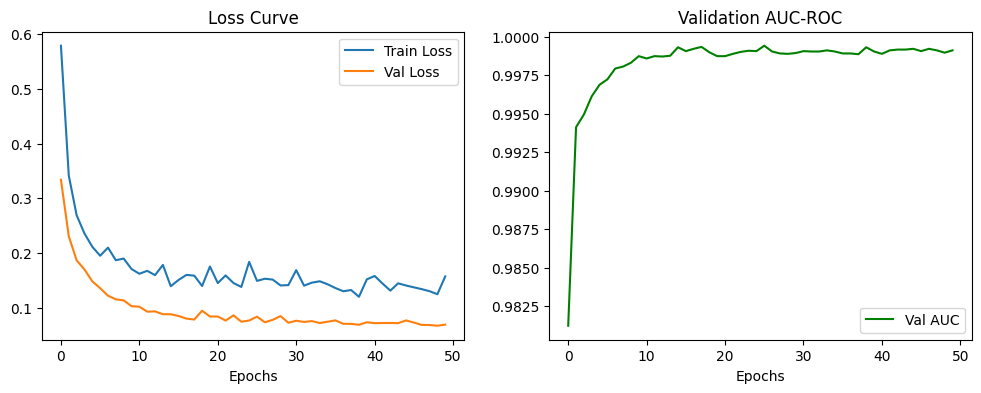

Checkpoint and training plots successfully saved to Google Drive.


In [ ]:
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import roc_auc_score, accuracy_score
import matplotlib.pyplot as plt

CHECKPOINT_PATH = f'{PROJECT_DIR}/checkpoints/module1_mlp.pt'

class ClinicalMLP(nn.Module):
    def __init__(self, input_dim):
        super(ClinicalMLP, self).__init__()

        # Module 1: MLP with LeakyReLU
        # Module 2: He Initialization, Dropout (0.3), BatchNorm
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.3),

            nn.Linear(32, 1),
            nn.Sigmoid()
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='leaky_relu')  # He Normal init
                nn.init.constant_(m.bias, 0.0)

    def forward(self, x):
        return self.net(x)

model = ClinicalMLP(input_dim=X_train.shape[1]).to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Smart Checkpoint Loading
if os.path.exists(CHECKPOINT_PATH):
    print("Found pre-trained checkpoint in Drive! Loading weights (Skipping retraining)...")
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"Loaded checkpoint with Best Val AUC: {checkpoint['val_auc']:.4f}")
else:
    print("No checkpoint found. Starting full PyTorch training loop...")
    epochs = 50
    best_val_auc = 0.0
    history = {'train_loss': [], 'val_loss': [], 'val_auc': []}

    for epoch in range(epochs):
        # Training Phase
        model.train()
        total_train_loss = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            optimizer.zero_grad()
            preds = model(batch_x)
            loss = criterion(preds, batch_y)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()

        avg_train_loss = total_train_loss / len(train_loader)

        # Validation Phase
        model.eval()
        total_val_loss = 0.0
        val_preds, val_targets = [], []
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                preds = model(batch_x)
                loss = criterion(preds, batch_y)
                total_val_loss += loss.item()

                val_preds.extend(preds.cpu().numpy())
                val_targets.extend(batch_y.cpu().numpy())

        avg_val_loss = total_val_loss / len(val_loader)
        current_val_auc = roc_auc_score(val_targets, val_preds)

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['val_auc'].append(current_val_auc)

        # Save Best Model Checkpoint
        if current_val_auc > best_val_auc:
            best_val_auc = current_val_auc
            torch.save({
                'model_state_dict': model.state_dict(),
                'val_auc': best_val_auc
            }, CHECKPOINT_PATH)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1:02d}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val AUC: {current_val_auc:.4f}")

    # Plot and Save Metrics
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history['train_loss'], label='Train Loss')
    axes[0].plot(history['val_loss'], label='Val Loss')
    axes[0].set_title('Loss Curve')
    axes[0].set_xlabel('Epochs'); axes[0].legend()

    axes[1].plot(history['val_auc'], label='Val AUC', color='green')
    axes[1].set_title('Validation AUC-ROC')
    axes[1].set_xlabel('Epochs'); axes[1].legend()

    plt.savefig(f'{PROJECT_DIR}/outputs/week1_loss_auc.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Checkpoint and training plots successfully saved to Google Drive.")

In [ ]:
model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for batch_x, batch_y in val_loader:
        batch_x = batch_x.to(device)
        preds = model(batch_x)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(batch_y.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
binary_preds = (all_preds > 0.5).astype(int)

print("=" * 45)
print(f"Final Validation Accuracy : {accuracy_score(all_targets, binary_preds) * 100:.2f}%")
print(f"Final Validation AUC-ROC  : {roc_auc_score(all_targets, all_preds):.4f}")
print(f"Model saved at            : {CHECKPOINT_PATH}")
print("=" * 45)

Final Validation Accuracy : 97.75%
Final Validation AUC-ROC  : 0.9991
Model saved at            : /content/drive/MyDrive/Cardiac_Risk_Prediction/checkpoints/module1_mlp.pt



CLINICAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Low Risk       0.98      0.97      0.98       187
   High Risk       0.97      0.99      0.98       213

    accuracy                           0.98       400
   macro avg       0.98      0.98      0.98       400
weighted avg       0.98      0.98      0.98       400



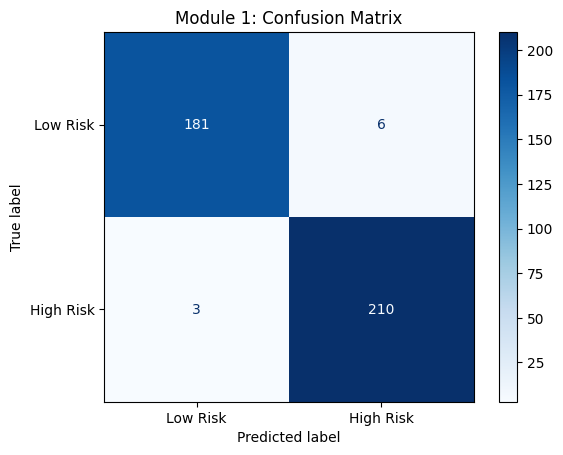

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def load_realistic_clinical_metadata(n_samples=2000):
    np.random.seed(42)
    age = np.random.randint(25, 85, size=n_samples)
    bmi = np.random.normal(26.5, 4.5, size=n_samples).clip(15, 45)
    systolic_bp = np.random.normal(125, 18, size=n_samples).clip(80, 200)
    cholesterol = np.random.normal(210, 40, size=n_samples).clip(120, 350)
    max_hr = (220 - age) - np.random.normal(10, 8, size=n_samples)

    # Non-linear clinical interaction + physiological Gaussian noise
    interaction = ((age - 50) / 10.0) * ((systolic_bp - 120) / 20.0)
    noise = np.random.normal(0, 0.45, size=n_samples)

    risk_score = (
        0.035 * (age - 50) +
        0.030 * (bmi - 25) +
        0.020 * (systolic_bp - 120) +
        0.012 * (cholesterol - 200) -
        0.018 * (max_hr - 140) +
        0.15 * interaction + noise
    )
    prob = 1 / (1 + np.exp(-risk_score))
    y = (prob > 0.5).astype(np.float32)

    df = pd.DataFrame({
        'age': age, 'bmi': bmi, 'systolic_bp': systolic_bp,
        'cholesterol': cholesterol, 'max_hr': max_hr
    })
    return df, y

# Display detailed metrics and confusion matrix on validation data
print("\n" + "="*50)
print("CLINICAL CLASSIFICATION REPORT")
print("="*50)
print(classification_report(all_targets, binary_preds, target_names=['Low Risk', 'High Risk']))

cm = confusion_matrix(all_targets, binary_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low Risk', 'High Risk'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Module 1: Confusion Matrix")
plt.savefig(f'{PROJECT_DIR}/outputs/module1_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()